# ShallowConvNet for EEG Classification

**ShallowConvNet** (Shallow Convolutional Network) is a lightweight deep learning architecture designed for EEG signal classification. It uses only 2 convolutional blocks to learn spectral features from raw EEG data.

**Key Features:**
- Shallow architecture with 2 convolutional blocks
- Optimized for spectral (frequency-domain) features
- Average pooling for dimensionality reduction
- Dropout for regularization
- Suitable for learning spectral patterns in EEG data

**Architecture:**
1. Temporal convolution (across time) - Wide kernel for spectral features
2. Spatial convolution (across channels) with average pooling
3. Dense classification layer

**Reference:** Schirrmeister et al. (2017) - "Deep learning with convolutional neural networks for EEG decoding and visualization"

**Comparison with DeepConvNet:**
- **ShallowConvNet**: 2 blocks, spectral features, faster training
- **DeepConvNet**: 4 blocks, hierarchical features, more complex patterns

---

**Dataset:**
- 4 classes: Apple, Car, Flower, Human Face
- 14 EEG channels × 128 time points = 1792 features
- 5-fold stratified cross-validation
- Training on GPU with PyTorch

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import (accuracy_score, precision_score, recall_score, 
                             f1_score, confusion_matrix, classification_report)

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader

import warnings
warnings.filterwarnings('ignore')

# Set random seeds for reproducibility
np.random.seed(42)
torch.manual_seed(42)
if torch.cuda.is_available():
    torch.cuda.manual_seed(42)
    torch.cuda.manual_seed_all(42)

# Set plotting style
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")

print("✅ All libraries imported successfully!")

✅ All libraries imported successfully!


In [2]:
# Check if GPU is available
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

print("="*60)
print("GPU INFORMATION")
print("="*60)
print(f"PyTorch Version: {torch.__version__}")
print(f"CUDA Available: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"CUDA Version: {torch.version.cuda}")
    print(f"GPU Device: {torch.cuda.get_device_name(0)}")
    print(f"GPU Memory: {torch.cuda.get_device_properties(0).total_memory / 1024**3:.2f} GB")
    print(f"Current Device: {device}")
else:
    print(f"Current Device: {device} (CPU)")
print("="*60)

GPU INFORMATION
PyTorch Version: 2.5.1+cu121
CUDA Available: True
CUDA Version: 12.1
GPU Device: NVIDIA GeForce RTX 4060 Laptop GPU
GPU Memory: 8.00 GB
Current Device: cuda


In [3]:
class ShallowConvNet(nn.Module):
    """
    ShallowConvNet for EEG classification.
    
    Shallow architecture with 2 convolutional blocks for learning spectral features.
    Based on Schirrmeister et al. (2017).
    
    Architecture:
    1. Temporal convolution (1, 25) - wide kernel for spectral features
    2. Spatial convolution (Chans, 1) - captures spatial patterns across channels
    3. Average pooling + Dropout
    4. Dense layer for classification
    
    Parameters:
        nb_classes (int): Number of output classes
        Chans (int): Number of EEG channels
        Samples (int): Number of time samples
        dropoutRate (float): Dropout probability
    """
    def __init__(self, nb_classes=4, Chans=14, Samples=128, dropoutRate=0.5):
        super(ShallowConvNet, self).__init__()
        
        self.nb_classes = nb_classes
        self.Chans = Chans
        self.Samples = Samples
        
        # Block 1: Temporal Convolution (wide kernel for spectral features)
        self.conv1 = nn.Conv2d(1, 40, (1, 25), bias=True)
        
        # Block 2: Spatial Convolution
        self.conv2 = nn.Conv2d(40, 40, (Chans, 1), bias=True)
        
        # Batch Normalization
        self.bn = nn.BatchNorm2d(40, eps=1e-05, momentum=0.1)
        
        # Average Pooling (larger pooling for shallow network)
        self.pool = nn.AvgPool2d((1, 75), stride=(1, 15))
        
        # Dropout
        self.dropout = nn.Dropout(dropoutRate)
        
        # Calculate output size after convolutions and pooling
        self._calculate_output_size()
        
        # Classification layer
        self.fc = nn.Linear(self.feature_size, nb_classes)
    
    def _calculate_output_size(self):
        """Calculate the output size after all conv and pooling layers."""
        # Create a dummy input to pass through the network in eval mode
        self.eval()
        with torch.no_grad():
            dummy_input = torch.zeros(1, 1, self.Chans, self.Samples)
            x = self.conv1(dummy_input)
            x = self.conv2(x)
            x = self.bn(x)
            x = torch.square(x)  # Squaring for power features
            x = self.pool(x)
            x = torch.log(torch.clamp(x, min=1e-7))  # Log for compression
            
            self.feature_size = x.numel()
        self.train()
    
    def forward(self, x):
        # Input shape: (batch, 1, Chans, Samples)
        
        # Temporal convolution
        x = self.conv1(x)
        
        # Spatial convolution
        x = self.conv2(x)
        
        # Batch normalization
        x = self.bn(x)
        
        # Squaring activation (power features)
        x = torch.square(x)
        
        # Average pooling
        x = self.pool(x)
        
        # Log activation (compression)
        x = torch.log(torch.clamp(x, min=1e-7))
        
        # Dropout
        x = self.dropout(x)
        
        # Flatten
        x = x.view(x.size(0), -1)
        
        # Classification
        x = self.fc(x)
        
        return x


# Test model initialization
print("Testing ShallowConvNet architecture...")
model_test = ShallowConvNet(nb_classes=4, Chans=14, Samples=128, dropoutRate=0.5)
test_input = torch.randn(2, 1, 14, 128)
test_output = model_test(test_input)
print(f"✅ ShallowConvNet initialized successfully!")
print(f"   Input shape: {test_input.shape}")
print(f"   Output shape: {test_output.shape}")
print(f"   Number of parameters: {sum(p.numel() for p in model_test.parameters()):,}")
print(f"   Trainable parameters: {sum(p.numel() for p in model_test.parameters() if p.requires_grad):,}")
print(f"   Feature size before FC: {model_test.feature_size}")

Testing ShallowConvNet architecture...
✅ ShallowConvNet initialized successfully!
   Input shape: torch.Size([2, 1, 14, 128])
   Output shape: torch.Size([2, 4])
   Number of parameters: 23,884
   Trainable parameters: 23,884
   Feature size before FC: 80


In [5]:
import os
def load_fold_data(fold_num):
    """
    Load training and testing data for a specific fold.
    
    Args:
        fold_num (int): Fold number (1-5)
    
    Returns:
        tuple: (X_train, y_train, X_test, y_test)
    """
    base_path = r'c:\Users\tranh\Documents\EEG-Foundation-Model-Paper\trainfold'
    fold_path = os.path.join(base_path, f'fold_{fold_num}')
    
    # Load training data
    train_df = pd.read_csv(os.path.join(fold_path, 'train.csv'))
    X_train = train_df.iloc[:, :-1].values
    y_train = train_df.iloc[:, -1].values
    
    # Load testing data
    test_df = pd.read_csv(os.path.join(fold_path, 'test.csv'))
    X_test = test_df.iloc[:, :-1].values
    y_test = test_df.iloc[:, -1].values
    
    return X_train, y_train, X_test, y_test


def preprocess_data(X_train, y_train, X_test, y_test):
    """
    Preprocess the data: standardization and label encoding.
    
    Args:
        X_train: Training features
        y_train: Training labels
        X_test: Testing features
        y_test: Testing labels
    
    Returns:
        tuple: (X_train_scaled, y_train_encoded, X_test_scaled, y_test_encoded, scaler, encoder)
    """
    # Standardize features
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)
    
    # Encode labels
    encoder = LabelEncoder()
    y_train_encoded = encoder.fit_transform(y_train)
    y_test_encoded = encoder.transform(y_test)
    
    return X_train_scaled, y_train_encoded, X_test_scaled, y_test_encoded, scaler, encoder


def prepare_eeg_data(X, num_channels=14, num_timepoints=128):
    """
    Reshape 1D EEG data to 4D tensor for CNN input.
    
    Args:
        X: Input data (samples, features)
        num_channels: Number of EEG channels
        num_timepoints: Number of time points
    
    Returns:
        torch.Tensor: Reshaped data (samples, 1, channels, timepoints)
    """
    # Reshape from (samples, 1792) to (samples, 14, 128)
    X_reshaped = X.reshape(-1, num_channels, num_timepoints)
    
    # Add channel dimension: (samples, 1, 14, 128)
    X_tensor = torch.FloatTensor(X_reshaped).unsqueeze(1)
    
    return X_tensor


# Test data loading
print("Testing data loading...")
X_train, y_train, X_test, y_test = load_fold_data(1)
print(f"✅ Fold 1 loaded successfully!")
print(f"   Train samples: {X_train.shape[0]}")
print(f"   Test samples: {X_test.shape[0]}")
print(f"   Features: {X_train.shape[1]}")
print(f"   Unique classes: {np.unique(y_train)}")

# Test preprocessing
X_train_scaled, y_train_encoded, X_test_scaled, y_test_encoded, scaler, encoder = preprocess_data(
    X_train, y_train, X_test, y_test
)
print(f"\n✅ Preprocessing successful!")
print(f"   Encoded classes: {encoder.classes_}")

# Test reshaping
X_train_tensor = prepare_eeg_data(X_train_scaled)
X_test_tensor = prepare_eeg_data(X_test_scaled)
print(f"\n✅ Data reshaping successful!")
print(f"   Train tensor shape: {X_train_tensor.shape}")
print(f"   Test tensor shape: {X_test_tensor.shape}")

Testing data loading...
✅ Fold 1 loaded successfully!
   Train samples: 2889
   Test samples: 723
   Features: 1792
   Unique classes: [1 2 3 4]

✅ Preprocessing successful!
   Encoded classes: [1 2 3 4]

✅ Data reshaping successful!
   Train tensor shape: torch.Size([2889, 1, 14, 128])
   Test tensor shape: torch.Size([723, 1, 14, 128])
✅ Fold 1 loaded successfully!
   Train samples: 2889
   Test samples: 723
   Features: 1792
   Unique classes: [1 2 3 4]

✅ Preprocessing successful!
   Encoded classes: [1 2 3 4]

✅ Data reshaping successful!
   Train tensor shape: torch.Size([2889, 1, 14, 128])
   Test tensor shape: torch.Size([723, 1, 14, 128])


In [6]:
def train_epoch(model, train_loader, criterion, optimizer, device):
    """
    Train the model for one epoch.
    
    Args:
        model: PyTorch model
        train_loader: DataLoader for training data
        criterion: Loss function
        optimizer: Optimizer
        device: Device to train on
    
    Returns:
        tuple: (average_loss, accuracy)
    """
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0
    
    for inputs, labels in train_loader:
        inputs, labels = inputs.to(device), labels.to(device)
        
        # Zero the parameter gradients
        optimizer.zero_grad()
        
        # Forward pass
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        
        # Backward pass and optimize
        loss.backward()
        optimizer.step()
        
        # Statistics
        running_loss += loss.item()
        _, predicted = torch.max(outputs.data, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()
    
    epoch_loss = running_loss / len(train_loader)
    epoch_acc = 100 * correct / total
    
    return epoch_loss, epoch_acc


def evaluate(model, test_loader, criterion, device):
    """
    Evaluate the model on test data.
    
    Args:
        model: PyTorch model
        test_loader: DataLoader for test data
        criterion: Loss function
        device: Device to evaluate on
    
    Returns:
        tuple: (average_loss, accuracy, all_labels, all_predictions)
    """
    model.eval()
    running_loss = 0.0
    correct = 0
    total = 0
    all_labels = []
    all_predictions = []
    
    with torch.no_grad():
        for inputs, labels in test_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            
            # Forward pass
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            
            # Statistics
            running_loss += loss.item()
            _, predicted = torch.max(outputs.data, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()
            
            # Store for metrics calculation
            all_labels.extend(labels.cpu().numpy())
            all_predictions.extend(predicted.cpu().numpy())
    
    epoch_loss = running_loss / len(test_loader)
    epoch_acc = 100 * correct / total
    
    return epoch_loss, epoch_acc, all_labels, all_predictions


print("✅ Training and evaluation functions defined successfully!")

✅ Training and evaluation functions defined successfully!


In [8]:
# Training hyperparameters
import time


BATCH_SIZE = 32
LEARNING_RATE = 0.001
NUM_EPOCHS = 100
PATIENCE = 15
NUM_FOLDS = 5

# Storage for results
fold_results = []
all_histories = []

print("="*80)
print("Starting 5-Fold Cross-Validation Training on GPU")
print("="*80)

for fold in range(1, NUM_FOLDS + 1):
    print(f"\n{'='*80}")
    print(f"FOLD {fold}/{NUM_FOLDS}")
    print(f"{'='*80}")
    
    # Load data for this fold
    X_train, y_train, X_test, y_test = load_fold_data(fold)
    
    # Preprocess data
    X_train_scaled, y_train_encoded, X_test_scaled, y_test_encoded, scaler, encoder = preprocess_data(
        X_train, y_train, X_test, y_test
    )
    
    # Prepare tensors
    X_train_tensor = prepare_eeg_data(X_train_scaled)
    X_test_tensor = prepare_eeg_data(X_test_scaled)
    y_train_tensor = torch.LongTensor(y_train_encoded)
    y_test_tensor = torch.LongTensor(y_test_encoded)
    
    # Create DataLoaders
    train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
    test_dataset = TensorDataset(X_test_tensor, y_test_tensor)
    train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
    test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)
    
    print(f"\nData loaded:")
    print(f"  Train samples: {len(train_dataset)}")
    print(f"  Test samples: {len(test_dataset)}")
    print(f"  Classes: {encoder.classes_}")
    
    # Initialize model
    model = ShallowConvNet(nb_classes=4, Chans=14, Samples=128, dropoutRate=0.5).to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE)
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=5, verbose=True)
    
    # Training history
    history = {
        'train_loss': [], 'train_acc': [],
        'test_loss': [], 'test_acc': []
    }
    
    # Early stopping variables
    best_test_acc = 0.0
    patience_counter = 0
    best_model_state = None
    
    print(f"\nTraining started...")
    start_time = time.time()
    
    for epoch in range(NUM_EPOCHS):
        # Train
        train_loss, train_acc = train_epoch(model, train_loader, criterion, optimizer, device)
        
        # Evaluate
        test_loss, test_acc, _, _ = evaluate(model, test_loader, criterion, device)
        
        # Update learning rate
        scheduler.step(test_loss)
        
        # Store history
        history['train_loss'].append(train_loss)
        history['train_acc'].append(train_acc)
        history['test_loss'].append(test_loss)
        history['test_acc'].append(test_acc)
        
        # Early stopping check
        if test_acc > best_test_acc:
            best_test_acc = test_acc
            patience_counter = 0
            best_model_state = model.state_dict().copy()
        else:
            patience_counter += 1
        
        # Print progress every 10 epochs
        if (epoch + 1) % 10 == 0:
            print(f"Epoch [{epoch+1}/{NUM_EPOCHS}] - "
                  f"Train Loss: {train_loss:.4f}, Train Acc: {train_acc:.2f}% | "
                  f"Test Loss: {test_loss:.4f}, Test Acc: {test_acc:.2f}% | "
                  f"Best Test Acc: {best_test_acc:.2f}%")
        
        # Early stopping
        if patience_counter >= PATIENCE:
            print(f"\n⚠️  Early stopping triggered at epoch {epoch+1}")
            break
    
    training_time = time.time() - start_time
    
    # Load best model
    model.load_state_dict(best_model_state)
    
    # Final evaluation
    _, final_acc, y_true, y_pred = evaluate(model, test_loader, criterion, device)
    
    # Calculate metrics
    precision = precision_score(y_true, y_pred, average='weighted', zero_division=0)
    recall = recall_score(y_true, y_pred, average='weighted', zero_division=0)
    f1_macro = f1_score(y_true, y_pred, average='macro', zero_division=0)
    f1_weighted = f1_score(y_true, y_pred, average='weighted', zero_division=0)
    
    # Confusion matrix
    cm = confusion_matrix(y_true, y_pred)
    
    # Store results
    fold_result = {
        'fold': fold,
        'accuracy': final_acc,
        'precision': precision * 100,
        'recall': recall * 100,
        'f1_macro': f1_macro * 100,
        'f1_weighted': f1_weighted * 100,
        'training_time': training_time,
        'epochs_trained': epoch + 1,
        'confusion_matrix': cm,
        'y_true': y_true,
        'y_pred': y_pred,
        'class_names': encoder.classes_
    }
    fold_results.append(fold_result)
    all_histories.append(history)
    
    print(f"\n{'='*80}")
    print(f"FOLD {fold} RESULTS:")
    print(f"{'='*80}")
    print(f"  Accuracy: {final_acc:.2f}%")
    print(f"  Precision: {precision*100:.2f}%")
    print(f"  Recall: {recall*100:.2f}%")
    print(f"  F1-Score (Macro): {f1_macro*100:.2f}%")
    print(f"  F1-Score (Weighted): {f1_weighted*100:.2f}%")
    print(f"  Training Time: {training_time:.2f}s")
    print(f"  Epochs Trained: {epoch + 1}")

print(f"\n{'='*80}")
print("5-FOLD CROSS-VALIDATION COMPLETED!")
print(f"{'='*80}")

Starting 5-Fold Cross-Validation Training on GPU

FOLD 1/5

Data loaded:
  Train samples: 2889
  Test samples: 723
  Classes: [1 2 3 4]

Training started...

Data loaded:
  Train samples: 2889
  Test samples: 723
  Classes: [1 2 3 4]

Training started...
Epoch [10/100] - Train Loss: 0.7816, Train Acc: 68.95% | Test Loss: 0.7668, Test Acc: 67.77% | Best Test Acc: 69.29%
Epoch [10/100] - Train Loss: 0.7816, Train Acc: 68.95% | Test Loss: 0.7668, Test Acc: 67.77% | Best Test Acc: 69.29%
Epoch [20/100] - Train Loss: 0.5788, Train Acc: 77.99% | Test Loss: 0.6239, Test Acc: 76.21% | Best Test Acc: 77.73%
Epoch [20/100] - Train Loss: 0.5788, Train Acc: 77.99% | Test Loss: 0.6239, Test Acc: 76.21% | Best Test Acc: 77.73%
Epoch [30/100] - Train Loss: 0.4869, Train Acc: 82.21% | Test Loss: 0.5698, Test Acc: 78.01% | Best Test Acc: 79.67%
Epoch [30/100] - Train Loss: 0.4869, Train Acc: 82.21% | Test Loss: 0.5698, Test Acc: 78.01% | Best Test Acc: 79.67%
Epoch [40/100] - Train Loss: 0.4150, Train 


OVERALL RESULTS SUMMARY

ACCURACY:
  Mean: 81.48%
  Std:  1.08%
  Min:  80.08%
  Max:  83.10%

PRECISION:
  Mean: 81.55%
  Std:  1.01%
  Min:  80.38%
  Max:  83.02%

RECALL:
  Mean: 81.48%
  Std:  1.08%
  Min:  80.08%
  Max:  83.10%

F1 MACRO:
  Mean: 80.64%
  Std:  1.09%
  Min:  79.25%
  Max:  82.28%

F1 WEIGHTED:
  Mean: 81.39%
  Std:  1.10%
  Min:  79.92%
  Max:  83.00%

AVERAGE TRAINING TIME: 47.84s
AVERAGE EPOCHS TRAINED: 66.2

✅ Visualization saved: shallowconvnet_results_summary.png

✅ Visualization saved: shallowconvnet_results_summary.png


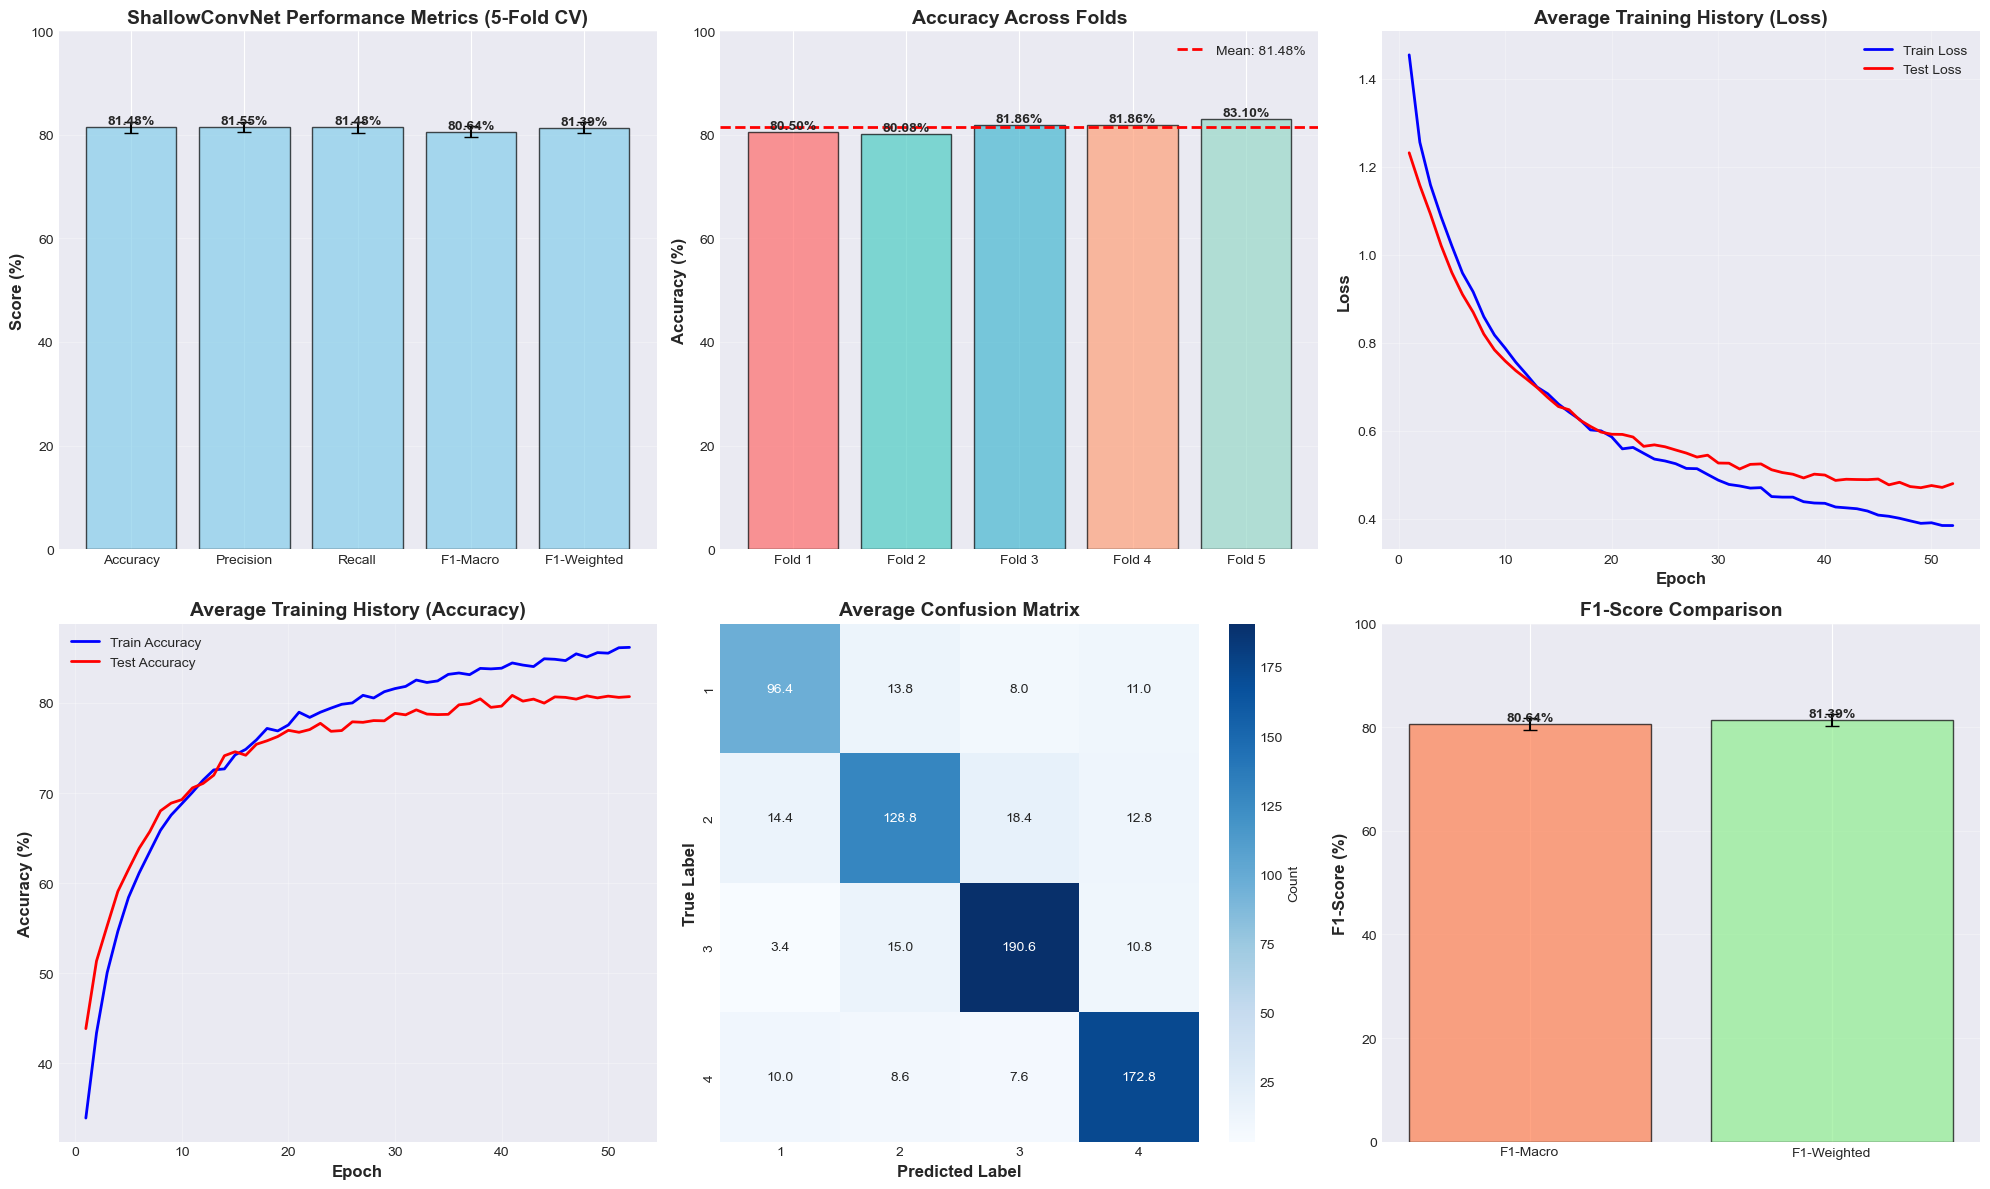

In [10]:
# Calculate overall statistics
metrics = ['accuracy', 'precision', 'recall', 'f1_macro', 'f1_weighted']
summary_stats = {}

print("\n" + "="*80)
print("OVERALL RESULTS SUMMARY")
print("="*80)

for metric in metrics:
    values = [result[metric] for result in fold_results]
    summary_stats[metric] = {
        'mean': np.mean(values),
        'std': np.std(values),
        'min': np.min(values),
        'max': np.max(values)
    }
    print(f"\n{metric.upper().replace('_', ' ')}:")
    print(f"  Mean: {summary_stats[metric]['mean']:.2f}%")
    print(f"  Std:  {summary_stats[metric]['std']:.2f}%")
    print(f"  Min:  {summary_stats[metric]['min']:.2f}%")
    print(f"  Max:  {summary_stats[metric]['max']:.2f}%")

# Average training time
avg_time = np.mean([result['training_time'] for result in fold_results])
avg_epochs = np.mean([result['epochs_trained'] for result in fold_results])
print(f"\nAVERAGE TRAINING TIME: {avg_time:.2f}s")
print(f"AVERAGE EPOCHS TRAINED: {avg_epochs:.1f}")

# Create visualization
fig = plt.figure(figsize=(20, 12))

# 1. Performance metrics comparison
ax1 = plt.subplot(2, 3, 1)
metric_names = ['Accuracy', 'Precision', 'Recall', 'F1-Macro', 'F1-Weighted']
metric_keys = ['accuracy', 'precision', 'recall', 'f1_macro', 'f1_weighted']
means = [summary_stats[key]['mean'] for key in metric_keys]
stds = [summary_stats[key]['std'] for key in metric_keys]

bars = ax1.bar(metric_names, means, yerr=stds, capsize=5, alpha=0.7, color='skyblue', edgecolor='black')
ax1.set_ylabel('Score (%)', fontsize=12, fontweight='bold')
ax1.set_title('ShallowConvNet Performance Metrics (5-Fold CV)', fontsize=14, fontweight='bold')
ax1.set_ylim([0, 100])
ax1.grid(axis='y', alpha=0.3)
for bar, mean in zip(bars, means):
    height = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2., height,
             f'{mean:.2f}%', ha='center', va='bottom', fontweight='bold')

# 2. Fold-wise accuracy comparison
ax2 = plt.subplot(2, 3, 2)
folds = [f"Fold {i}" for i in range(1, 6)]
accuracies = [result['accuracy'] for result in fold_results]
colors = ['#FF6B6B', '#4ECDC4', '#45B7D1', '#FFA07A', '#98D8C8']
bars = ax2.bar(folds, accuracies, alpha=0.7, color=colors, edgecolor='black')
ax2.axhline(y=summary_stats['accuracy']['mean'], color='red', linestyle='--', 
            label=f"Mean: {summary_stats['accuracy']['mean']:.2f}%", linewidth=2)
ax2.set_ylabel('Accuracy (%)', fontsize=12, fontweight='bold')
ax2.set_title('Accuracy Across Folds', fontsize=14, fontweight='bold')
ax2.set_ylim([0, 100])
ax2.legend()
ax2.grid(axis='y', alpha=0.3)
for bar, acc in zip(bars, accuracies):
    height = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width()/2., height,
             f'{acc:.2f}%', ha='center', va='bottom', fontweight='bold')

# 3. Training history (average across folds)
ax3 = plt.subplot(2, 3, 3)
# Find minimum length across all folds (due to early stopping)
min_epochs = min(len(h['train_loss']) for h in all_histories)
# Truncate all histories to minimum length
train_losses_truncated = [h['train_loss'][:min_epochs] for h in all_histories]
test_losses_truncated = [h['test_loss'][:min_epochs] for h in all_histories]
avg_train_loss = np.mean(train_losses_truncated, axis=0)
avg_test_loss = np.mean(test_losses_truncated, axis=0)
epochs_range = range(1, min_epochs + 1)
ax3.plot(epochs_range, avg_train_loss, 'b-', label='Train Loss', linewidth=2)
ax3.plot(epochs_range, avg_test_loss, 'r-', label='Test Loss', linewidth=2)
ax3.set_xlabel('Epoch', fontsize=12, fontweight='bold')
ax3.set_ylabel('Loss', fontsize=12, fontweight='bold')
ax3.set_title('Average Training History (Loss)', fontsize=14, fontweight='bold')
ax3.legend()
ax3.grid(True, alpha=0.3)

# 4. Training history (accuracy)
ax4 = plt.subplot(2, 3, 4)
# Truncate accuracy histories to minimum length
train_accs_truncated = [h['train_acc'][:min_epochs] for h in all_histories]
test_accs_truncated = [h['test_acc'][:min_epochs] for h in all_histories]
avg_train_acc = np.mean(train_accs_truncated, axis=0)
avg_test_acc = np.mean(test_accs_truncated, axis=0)
ax4.plot(epochs_range, avg_train_acc, 'b-', label='Train Accuracy', linewidth=2)
ax4.plot(epochs_range, avg_test_acc, 'r-', label='Test Accuracy', linewidth=2)
ax4.set_xlabel('Epoch', fontsize=12, fontweight='bold')
ax4.set_ylabel('Accuracy (%)', fontsize=12, fontweight='bold')
ax4.set_title('Average Training History (Accuracy)', fontsize=14, fontweight='bold')
ax4.legend()
ax4.grid(True, alpha=0.3)

# 5. Confusion matrix (averaged)
ax5 = plt.subplot(2, 3, 5)
avg_cm = np.mean([result['confusion_matrix'] for result in fold_results], axis=0)
class_names = fold_results[0]['class_names']
sns.heatmap(avg_cm, annot=True, fmt='.1f', cmap='Blues', 
            xticklabels=class_names, yticklabels=class_names, ax=ax5, cbar_kws={'label': 'Count'})
ax5.set_ylabel('True Label', fontsize=12, fontweight='bold')
ax5.set_xlabel('Predicted Label', fontsize=12, fontweight='bold')
ax5.set_title('Average Confusion Matrix', fontsize=14, fontweight='bold')

# 6. F1-Score comparison
ax6 = plt.subplot(2, 3, 6)
f1_metrics = ['F1-Macro', 'F1-Weighted']
f1_values = [summary_stats['f1_macro']['mean'], summary_stats['f1_weighted']['mean']]
f1_stds = [summary_stats['f1_macro']['std'], summary_stats['f1_weighted']['std']]
bars = ax6.bar(f1_metrics, f1_values, yerr=f1_stds, capsize=5, 
               alpha=0.7, color=['coral', 'lightgreen'], edgecolor='black')
ax6.set_ylabel('F1-Score (%)', fontsize=12, fontweight='bold')
ax6.set_title('F1-Score Comparison', fontsize=14, fontweight='bold')
ax6.set_ylim([0, 100])
ax6.grid(axis='y', alpha=0.3)
for bar, val in zip(bars, f1_values):
    height = bar.get_height()
    ax6.text(bar.get_x() + bar.get_width()/2., height,
             f'{val:.2f}%', ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.savefig('shallowconvnet_results_summary.png', dpi=300, bbox_inches='tight')
print("\n✅ Visualization saved: shallowconvnet_results_summary.png")
plt.show()

print("\n" + "="*80)

In [11]:
# 1. Results summary CSV
summary_df = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1-Macro', 'F1-Weighted'],
    'Mean (%)': [summary_stats[key]['mean'] for key in metric_keys],
    'Std (%)': [summary_stats[key]['std'] for key in metric_keys],
    'Min (%)': [summary_stats[key]['min'] for key in metric_keys],
    'Max (%)': [summary_stats[key]['max'] for key in metric_keys]
})
summary_df.to_csv('shallowconvnet_results_summary.csv', index=False)
print("✅ Saved: shallowconvnet_results_summary.csv")

# 2. Fold details CSV
fold_details = []
for result in fold_results:
    fold_details.append({
        'Fold': result['fold'],
        'Accuracy (%)': result['accuracy'],
        'Precision (%)': result['precision'],
        'Recall (%)': result['recall'],
        'F1-Macro (%)': result['f1_macro'],
        'F1-Weighted (%)': result['f1_weighted'],
        'Training Time (s)': result['training_time'],
        'Epochs Trained': result['epochs_trained']
    })
fold_df = pd.DataFrame(fold_details)
fold_df.to_csv('shallowconvnet_fold_details.csv', index=False)
print("✅ Saved: shallowconvnet_fold_details.csv")

# 3. Confusion matrices CSV
cm_data = []
for result in fold_results:
    cm = result['confusion_matrix']
    for i, true_class in enumerate(result['class_names']):
        for j, pred_class in enumerate(result['class_names']):
            cm_data.append({
                'Fold': result['fold'],
                'True Class': true_class,
                'Predicted Class': pred_class,
                'Count': cm[i, j]
            })
cm_df = pd.DataFrame(cm_data)
cm_df.to_csv('shallowconvnet_confusion_matrix.csv', index=False)
print("✅ Saved: shallowconvnet_confusion_matrix.csv")

# Display summary
print("\n" + "="*80)
print("FINAL SUMMARY")
print("="*80)
print("\nShallowConvNet Results:")
print(summary_df.to_string(index=False))
print(f"\nAverage Training Time: {avg_time:.2f}s")
print(f"Average Epochs Trained: {avg_epochs:.1f}")
print("\n✅ All results saved successfully!")
print("="*80)

✅ Saved: shallowconvnet_results_summary.csv
✅ Saved: shallowconvnet_fold_details.csv
✅ Saved: shallowconvnet_confusion_matrix.csv

FINAL SUMMARY

ShallowConvNet Results:
     Metric  Mean (%)  Std (%)   Min (%)   Max (%)
   Accuracy 81.479063 1.079933 80.082988 83.102493
  Precision 81.553653 1.013614 80.380479 83.018751
     Recall 81.479063 1.079933 80.082988 83.102493
   F1-Macro 80.636779 1.087931 79.247444 82.282827
F1-Weighted 81.394575 1.102728 79.922703 83.001470

Average Training Time: 47.84s
Average Epochs Trained: 66.2

✅ All results saved successfully!


In [12]:
# Analyze overfitting for each fold
overfitting_analysis = []

print("\n" + "="*80)
print("OVERFITTING ANALYSIS")
print("="*80)

for fold_idx, (result, history) in enumerate(zip(fold_results, all_histories), 1):
    # Get final epoch values
    final_train_acc = history['train_acc'][-1]
    final_test_acc = history['test_acc'][-1]
    final_train_loss = history['train_loss'][-1]
    final_test_loss = history['test_loss'][-1]
    
    # Calculate gaps
    acc_gap = final_train_acc - final_test_acc
    loss_gap = final_test_loss - final_train_loss
    
    # Determine severity
    if acc_gap > 20:
        severity = "🔴 SEVERE"
    elif acc_gap > 10:
        severity = "🟡 MODERATE"
    elif acc_gap > 5:
        severity = "🟢 MILD"
    else:
        severity = "✅ MINIMAL"
    
    overfitting_analysis.append({
        'Fold': fold_idx,
        'Train Accuracy (%)': final_train_acc,
        'Test Accuracy (%)': final_test_acc,
        'Accuracy Gap (%)': acc_gap,
        'Train Loss': final_train_loss,
        'Test Loss': final_test_loss,
        'Loss Gap': loss_gap,
        'Severity': severity
    })
    
    print(f"\nFold {fold_idx}:")
    print(f"  Train Accuracy: {final_train_acc:.2f}%")
    print(f"  Test Accuracy:  {final_test_acc:.2f}%")
    print(f"  Accuracy Gap:   {acc_gap:.2f}% {severity}")
    print(f"  Train Loss:     {final_train_loss:.4f}")
    print(f"  Test Loss:      {final_test_loss:.4f}")
    print(f"  Loss Gap:       {loss_gap:.4f}")

# Calculate average overfitting metrics
avg_acc_gap = np.mean([x['Accuracy Gap (%)'] for x in overfitting_analysis])
avg_loss_gap = np.mean([x['Loss Gap'] for x in overfitting_analysis])

print(f"\n{'='*80}")
print(f"AVERAGE OVERFITTING METRICS:")
print(f"{'='*80}")
print(f"  Average Accuracy Gap: {avg_acc_gap:.2f}%")
print(f"  Average Loss Gap:     {avg_loss_gap:.4f}")

if avg_acc_gap > 20:
    overall_severity = "🔴 SEVERE"
    recommendation = "Consider: 1) Stronger regularization, 2) More dropout, 3) Data augmentation"
elif avg_acc_gap > 10:
    overall_severity = "🟡 MODERATE"
    recommendation = "Consider: 1) Increasing dropout rate, 2) Adding regularization"
elif avg_acc_gap > 5:
    overall_severity = "🟢 MILD"
    recommendation = "Model is reasonably well-generalized"
else:
    overall_severity = "✅ MINIMAL"
    recommendation = "Excellent generalization!"

print(f"  Overall Severity:     {overall_severity}")
print(f"  Recommendation:       {recommendation}")

# Save overfitting analysis
overfitting_df = pd.DataFrame(overfitting_analysis)
overfitting_df.to_csv('shallowconvnet_overfitting_analysis.csv', index=False)
print(f"\n✅ Saved: shallowconvnet_overfitting_analysis.csv")
print("="*80)


OVERFITTING ANALYSIS

Fold 1:
  Train Accuracy: 87.19%
  Test Accuracy:  80.50%
  Accuracy Gap:   6.69% 🟢 MILD
  Train Loss:     0.3698
  Test Loss:      0.5091
  Loss Gap:       0.1393

Fold 2:
  Train Accuracy: 85.98%
  Test Accuracy:  80.08%
  Accuracy Gap:   5.90% 🟢 MILD
  Train Loss:     0.3810
  Test Loss:      0.4669
  Loss Gap:       0.0859

Fold 3:
  Train Accuracy: 88.17%
  Test Accuracy:  81.86%
  Accuracy Gap:   6.31% 🟢 MILD
  Train Loss:     0.3324
  Test Loss:      0.4261
  Loss Gap:       0.0937

Fold 4:
  Train Accuracy: 87.85%
  Test Accuracy:  81.86%
  Accuracy Gap:   6.00% 🟢 MILD
  Train Loss:     0.3521
  Test Loss:      0.4580
  Loss Gap:       0.1059

Fold 5:
  Train Accuracy: 88.48%
  Test Accuracy:  83.10%
  Accuracy Gap:   5.38% 🟢 MILD
  Train Loss:     0.3193
  Test Loss:      0.4263
  Loss Gap:       0.1070

AVERAGE OVERFITTING METRICS:
  Average Accuracy Gap: 6.06%
  Average Loss Gap:     0.1064
  Overall Severity:     🟢 MILD
  Recommendation:       Model i

✅ Visualization saved: shallowconvnet_overfitting_analysis.png


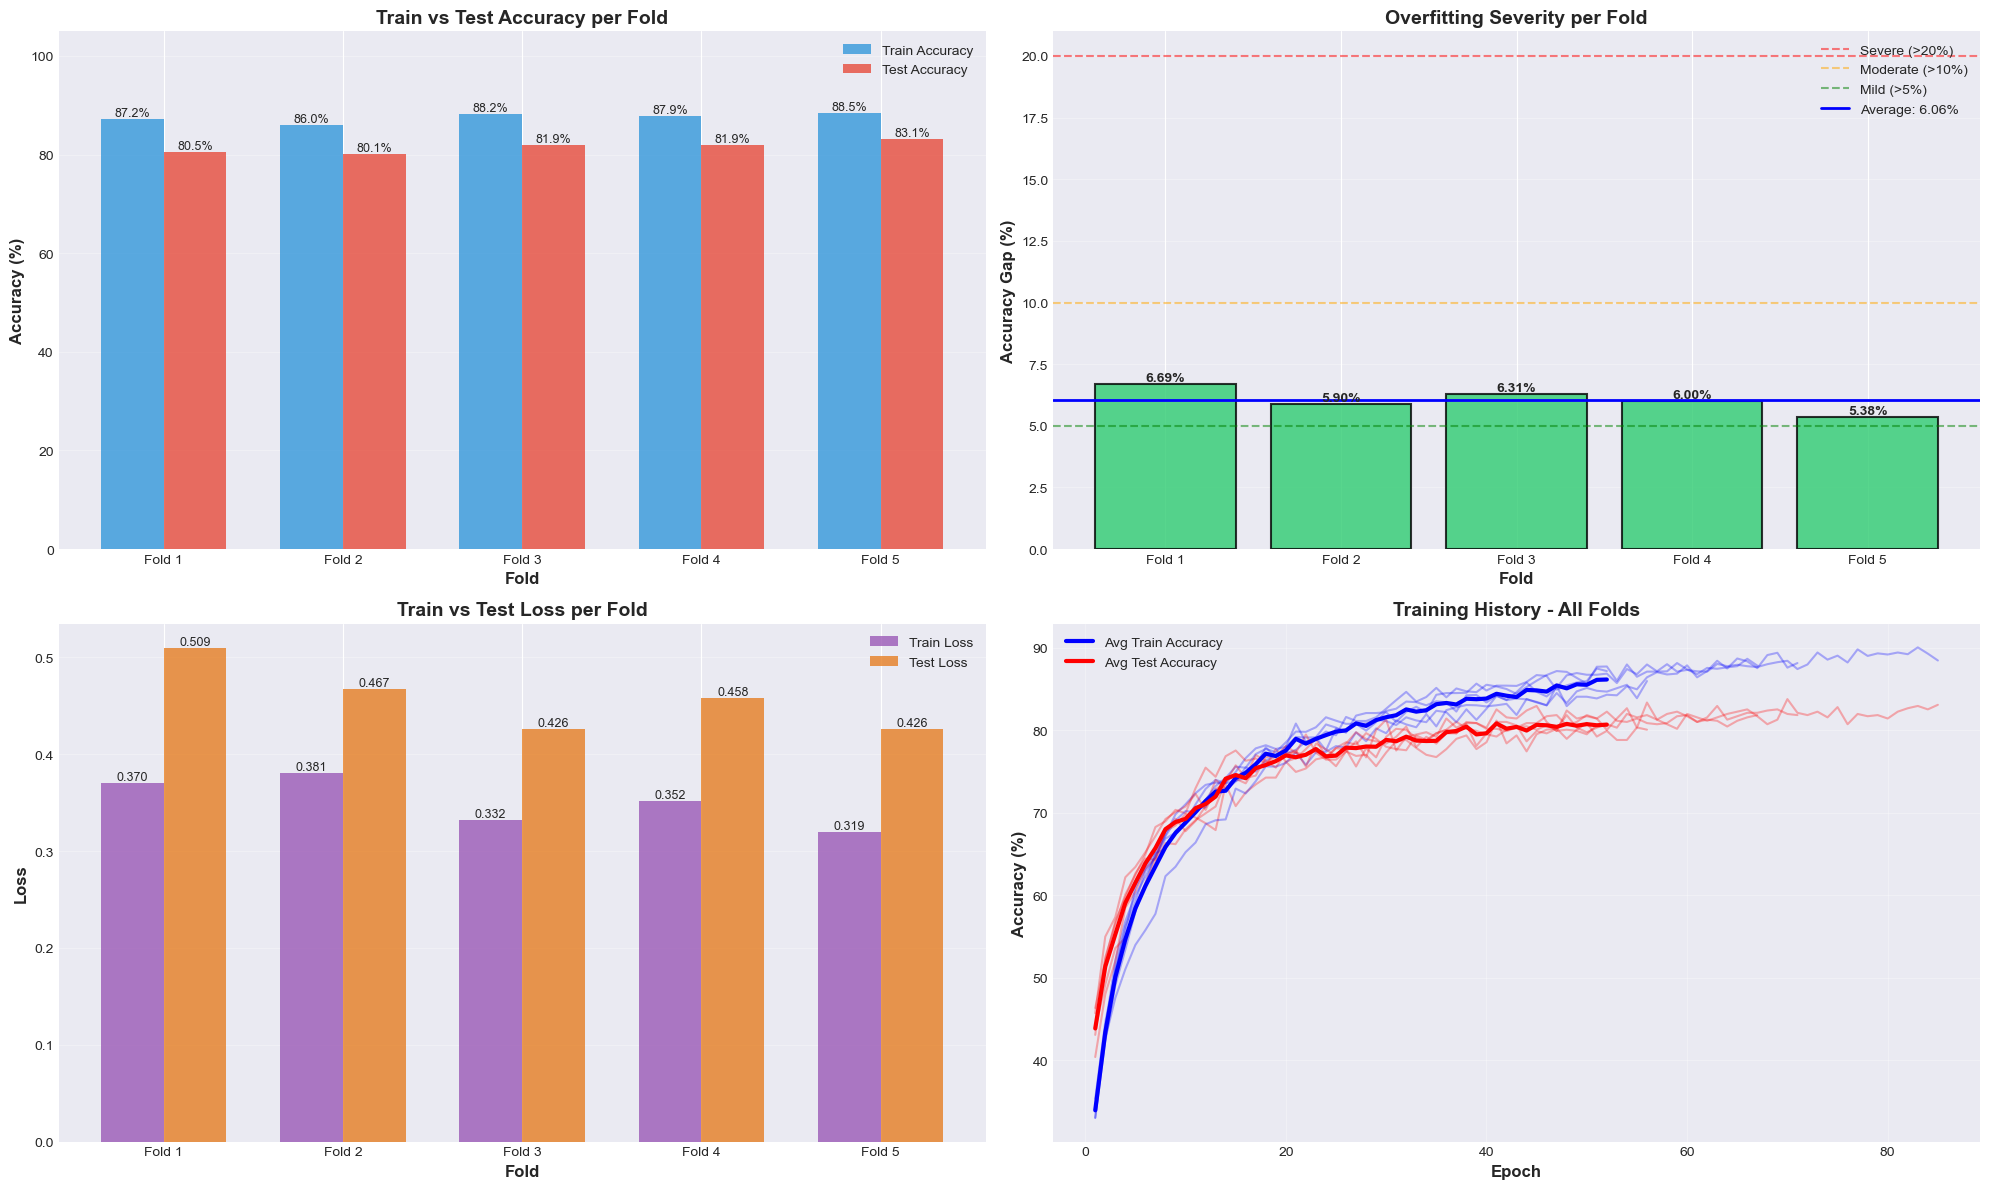

In [15]:
# Create comprehensive overfitting visualization
fig = plt.figure(figsize=(20, 12))

# 1. Train vs Test Accuracy for each fold
ax1 = plt.subplot(2, 2, 1)
folds = [f"Fold {i}" for i in range(1, 6)]
train_accs = [x['Train Accuracy (%)'] for x in overfitting_analysis]
test_accs = [x['Test Accuracy (%)'] for x in overfitting_analysis]

x = np.arange(len(folds))
width = 0.35
bars1 = ax1.bar(x - width/2, train_accs, width, label='Train Accuracy', alpha=0.8, color='#3498db')
bars2 = ax1.bar(x + width/2, test_accs, width, label='Test Accuracy', alpha=0.8, color='#e74c3c')

ax1.set_xlabel('Fold', fontsize=12, fontweight='bold')
ax1.set_ylabel('Accuracy (%)', fontsize=12, fontweight='bold')
ax1.set_title('Train vs Test Accuracy per Fold', fontsize=14, fontweight='bold')
ax1.set_xticks(x)
ax1.set_xticklabels(folds)
ax1.legend()
ax1.grid(axis='y', alpha=0.3)
ax1.set_ylim([0, 105])

# Add value labels
for bars in [bars1, bars2]:
    for bar in bars:
        height = bar.get_height()
        ax1.text(bar.get_x() + bar.get_width()/2., height,
                f'{height:.1f}%', ha='center', va='bottom', fontsize=9)

# 2. Accuracy Gap per Fold
ax2 = plt.subplot(2, 2, 2)
acc_gaps = [x['Accuracy Gap (%)'] for x in overfitting_analysis]
colors = ['#e74c3c' if gap > 20 else '#f39c12' if gap > 10 else '#2ecc71' if gap > 5 else '#27ae60' 
          for gap in acc_gaps]
bars = ax2.bar(folds, acc_gaps, alpha=0.8, color=colors, edgecolor='black', linewidth=1.5)

ax2.axhline(y=20, color='red', linestyle='--', alpha=0.5, label='Severe (>20%)')
ax2.axhline(y=10, color='orange', linestyle='--', alpha=0.5, label='Moderate (>10%)')
ax2.axhline(y=5, color='green', linestyle='--', alpha=0.5, label='Mild (>5%)')
ax2.axhline(y=avg_acc_gap, color='blue', linestyle='-', linewidth=2, label=f'Average: {avg_acc_gap:.2f}%')

ax2.set_xlabel('Fold', fontsize=12, fontweight='bold')
ax2.set_ylabel('Accuracy Gap (%)', fontsize=12, fontweight='bold')
ax2.set_title('Overfitting Severity per Fold', fontsize=14, fontweight='bold')
ax2.legend(loc='upper right')
ax2.grid(axis='y', alpha=0.3)

# Add value labels
for bar, gap in zip(bars, acc_gaps):
    height = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width()/2., height,
            f'{gap:.2f}%', ha='center', va='bottom', fontweight='bold')

# 3. Loss Gap Analysis
ax3 = plt.subplot(2, 2, 3)
train_losses = [x['Train Loss'] for x in overfitting_analysis]
test_losses = [x['Test Loss'] for x in overfitting_analysis]

x = np.arange(len(folds))
bars1 = ax3.bar(x - width/2, train_losses, width, label='Train Loss', alpha=0.8, color='#9b59b6')
bars2 = ax3.bar(x + width/2, test_losses, width, label='Test Loss', alpha=0.8, color='#e67e22')

ax3.set_xlabel('Fold', fontsize=12, fontweight='bold')
ax3.set_ylabel('Loss', fontsize=12, fontweight='bold')
ax3.set_title('Train vs Test Loss per Fold', fontsize=14, fontweight='bold')
ax3.set_xticks(x)
ax3.set_xticklabels(folds)
ax3.legend()
ax3.grid(axis='y', alpha=0.3)

# Add value labels
for bars in [bars1, bars2]:
    for bar in bars:
        height = bar.get_height()
        ax3.text(bar.get_x() + bar.get_width()/2., height,
                f'{height:.3f}', ha='center', va='bottom', fontsize=9)

# 4. Training History - All Folds
ax4 = plt.subplot(2, 2, 4)
for fold_idx, history in enumerate(all_histories, 1):
    epochs = range(1, len(history['train_acc']) + 1)
    ax4.plot(epochs, history['train_acc'], linestyle='-', alpha=0.3, color='blue')
    ax4.plot(epochs, history['test_acc'], linestyle='-', alpha=0.3, color='red')

# Plot average - truncate to minimum length
min_epochs_overfitting = min(len(h['train_acc']) for h in all_histories)
train_accs_truncated_overfitting = [h['train_acc'][:min_epochs_overfitting] for h in all_histories]
test_accs_truncated_overfitting = [h['test_acc'][:min_epochs_overfitting] for h in all_histories]
avg_train_acc = np.mean(train_accs_truncated_overfitting, axis=0)
avg_test_acc = np.mean(test_accs_truncated_overfitting, axis=0)
epochs = range(1, min_epochs_overfitting + 1)
ax4.plot(epochs, avg_train_acc, 'b-', linewidth=3, label='Avg Train Accuracy')
ax4.plot(epochs, avg_test_acc, 'r-', linewidth=3, label='Avg Test Accuracy')

ax4.set_xlabel('Epoch', fontsize=12, fontweight='bold')
ax4.set_ylabel('Accuracy (%)', fontsize=12, fontweight='bold')
ax4.set_title('Training History - All Folds', fontsize=14, fontweight='bold')
ax4.legend()
ax4.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('shallowconvnet_overfitting_analysis.png', dpi=300, bbox_inches='tight')
print("✅ Visualization saved: shallowconvnet_overfitting_analysis.png")
plt.show()

In [17]:
# Calculate per-class accuracy for each fold
per_class_results = []

print("\n" + "="*80)
print("PER-CLASS ACCURACY ANALYSIS")
print("="*80)

for fold_idx, result in enumerate(fold_results, 1):
    y_true = result['y_true']
    y_pred = result['y_pred']
    class_names = result['class_names']
    
    print(f"\nFold {fold_idx}:")
    print("-" * 60)
    
    for class_idx, class_name in enumerate(class_names):
        # Find all instances of this class
        class_mask = np.array(y_true) == class_idx
        class_true = np.array(y_true)[class_mask]
        class_pred = np.array(y_pred)[class_mask]
        
        # Calculate accuracy for this class
        if len(class_true) > 0:
            class_acc = 100 * np.sum(class_true == class_pred) / len(class_true)
        else:
            class_acc = 0.0
        
        per_class_results.append({
            'Fold': fold_idx,
            'Class': class_name,
            'Accuracy (%)': class_acc,
            'Sample Count': len(class_true)
        })
        
        print(f"  {str(class_name):15s}: {class_acc:6.2f}% ({len(class_true)} samples)")

# Convert to DataFrame
per_class_df = pd.DataFrame(per_class_results)

# Calculate average per-class accuracy across folds
print(f"\n{'='*80}")
print("AVERAGE PER-CLASS ACCURACY ACROSS FOLDS")
print(f"{'='*80}")

class_names = fold_results[0]['class_names']
for class_name in class_names:
    class_data = per_class_df[per_class_df['Class'] == class_name]
    mean_acc = class_data['Accuracy (%)'].mean()
    std_acc = class_data['Accuracy (%)'].std()
    min_acc = class_data['Accuracy (%)'].min()
    max_acc = class_data['Accuracy (%)'].max()
    
    print(f"\n{class_name}:")
    print(f"  Mean Accuracy: {mean_acc:.2f}% ± {std_acc:.2f}%")
    print(f"  Min:  {min_acc:.2f}%")
    print(f"  Max:  {max_acc:.2f}%")

# Identify best and worst performing classes
avg_per_class = per_class_df.groupby('Class')['Accuracy (%)'].mean().sort_values(ascending=False)
best_class = avg_per_class.index[0]
worst_class = avg_per_class.index[-1]

print(f"\n{'='*80}")
print(f"✅ Best Performing Class:  {best_class} ({avg_per_class[best_class]:.2f}%)")
print(f"⚠️  Worst Performing Class: {worst_class} ({avg_per_class[worst_class]:.2f}%)")
print(f"{'='*80}")

# Save per-class results
per_class_df.to_csv('shallowconvnet_per_class_accuracy.csv', index=False)
print(f"\n✅ Saved: shallowconvnet_per_class_accuracy.csv")


PER-CLASS ACCURACY ANALYSIS

Fold 1:
------------------------------------------------------------
  1              :  77.69% (130 samples)
  2              :  70.11% (174 samples)
  3              :  86.36% (220 samples)
  4              :  84.92% (199 samples)

Fold 2:
------------------------------------------------------------
  1              :  65.89% (129 samples)
  2              :  76.00% (175 samples)
  3              :  84.55% (220 samples)
  4              :  87.94% (199 samples)

Fold 3:
------------------------------------------------------------
  1              :  73.64% (129 samples)
  2              :  71.43% (175 samples)
  3              :  89.50% (219 samples)
  4              :  87.94% (199 samples)

Fold 4:
------------------------------------------------------------
  1              :  79.84% (129 samples)
  2              :  76.44% (174 samples)
  3              :  85.45% (220 samples)
  4              :  83.92% (199 samples)

Fold 5:
--------------------------

✅ Visualization saved: shallowconvnet_per_class_accuracy.png


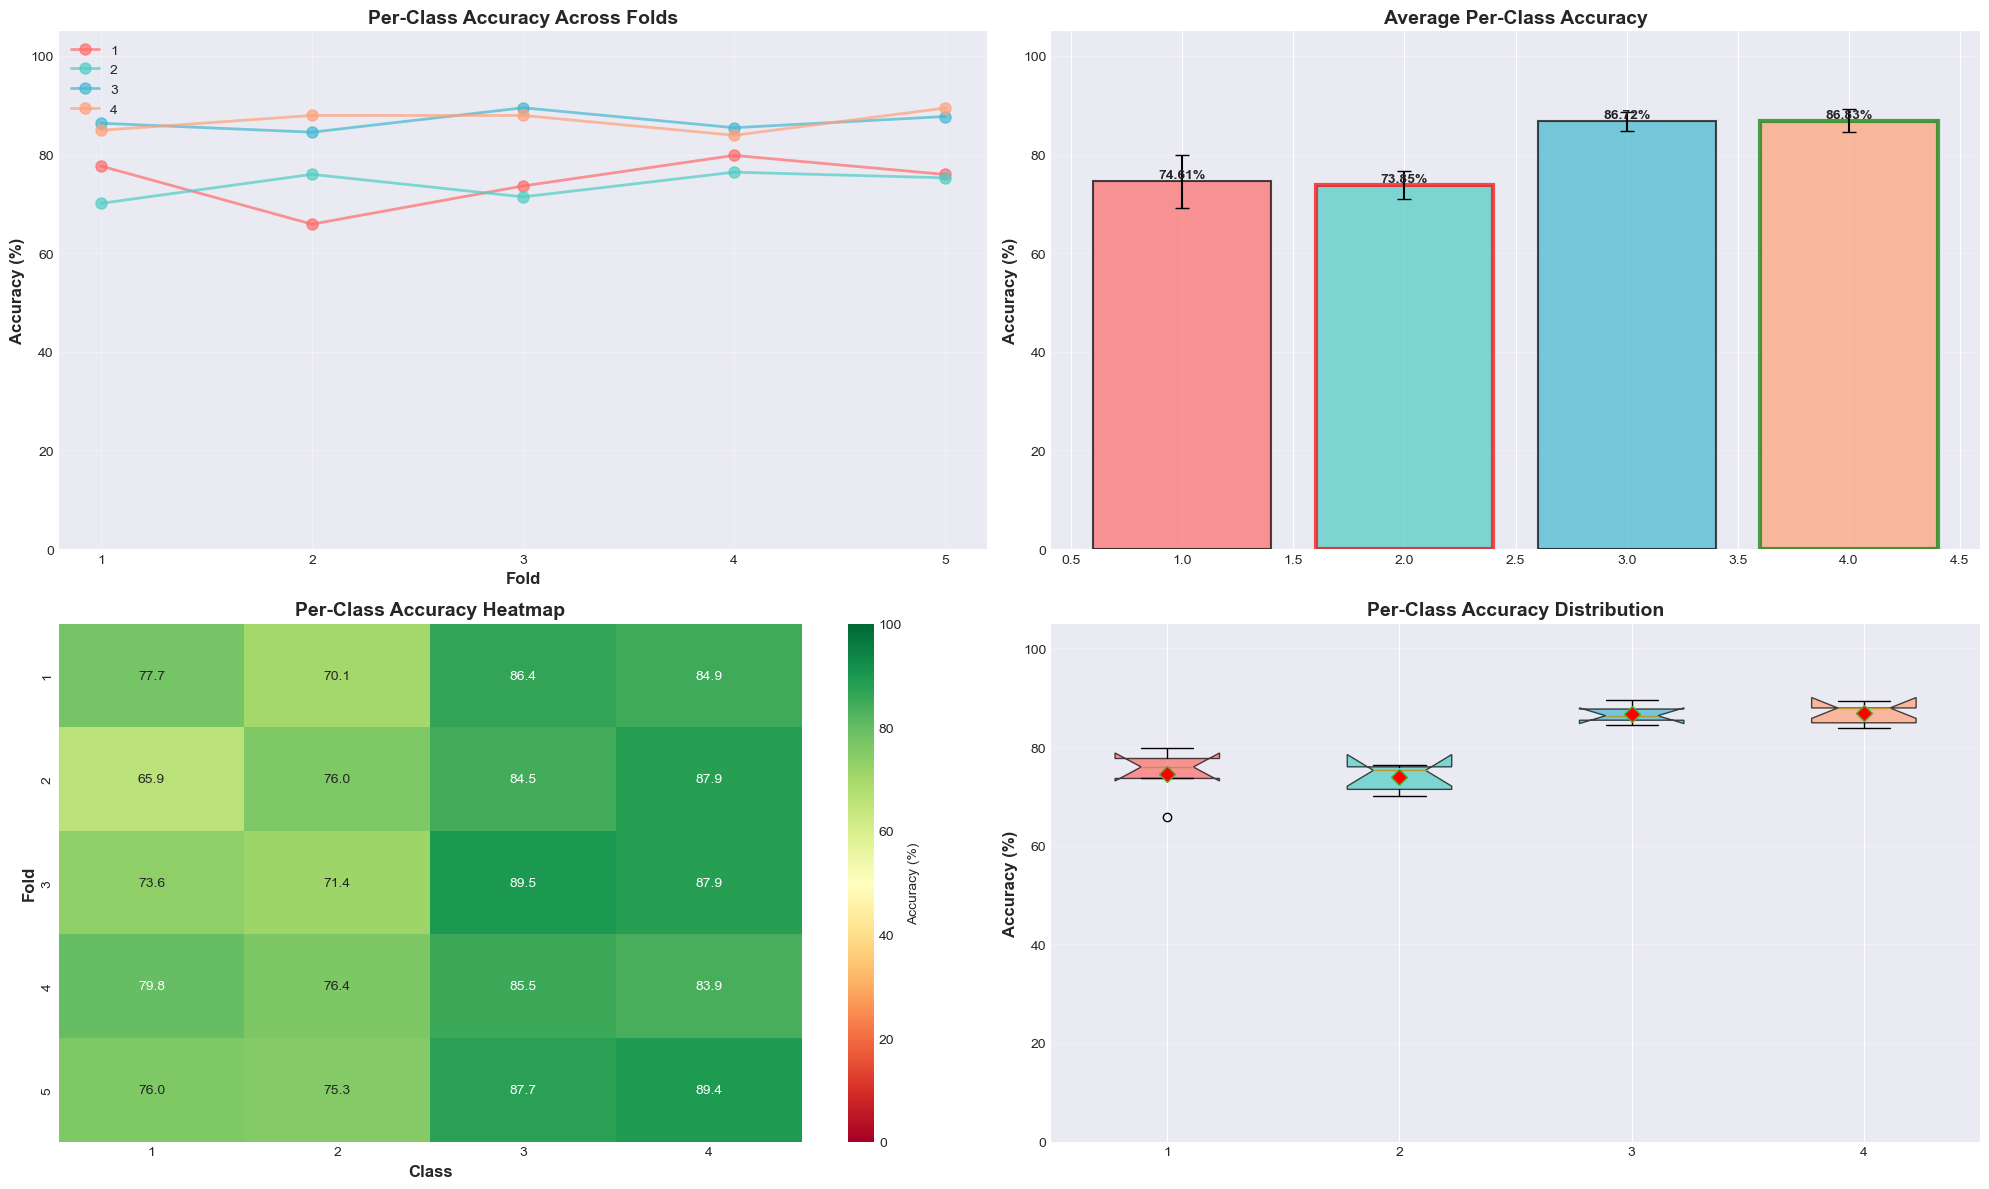


✅ ShallowConvNet Training Complete!


In [18]:
# Create comprehensive per-class accuracy visualization
fig = plt.figure(figsize=(20, 12))

class_names = fold_results[0]['class_names']
colors = ['#FF6B6B', '#4ECDC4', '#45B7D1', '#FFA07A']

# 1. Per-Class Accuracy Across Folds (Line Plot)
ax1 = plt.subplot(2, 2, 1)
for class_name, color in zip(class_names, colors):
    class_data = per_class_df[per_class_df['Class'] == class_name]
    folds = class_data['Fold'].values
    accuracies = class_data['Accuracy (%)'].values
    ax1.plot(folds, accuracies, marker='o', linewidth=2, markersize=8, 
             label=class_name, color=color, alpha=0.7)

ax1.set_xlabel('Fold', fontsize=12, fontweight='bold')
ax1.set_ylabel('Accuracy (%)', fontsize=12, fontweight='bold')
ax1.set_title('Per-Class Accuracy Across Folds', fontsize=14, fontweight='bold')
ax1.set_xticks(range(1, NUM_FOLDS + 1))
ax1.legend(loc='best', fontsize=10)
ax1.grid(True, alpha=0.3)
ax1.set_ylim([0, 105])

# 2. Average Per-Class Accuracy (Bar Plot)
ax2 = plt.subplot(2, 2, 2)
avg_per_class = per_class_df.groupby('Class')['Accuracy (%)'].agg(['mean', 'std'])
bars = ax2.bar(avg_per_class.index, avg_per_class['mean'], 
               yerr=avg_per_class['std'], capsize=5, 
               alpha=0.7, color=colors, edgecolor='black', linewidth=1.5)

ax2.set_ylabel('Accuracy (%)', fontsize=12, fontweight='bold')
ax2.set_title('Average Per-Class Accuracy', fontsize=14, fontweight='bold')
ax2.set_ylim([0, 105])
ax2.grid(axis='y', alpha=0.3)

# Add value labels
for bar, (idx, row) in zip(bars, avg_per_class.iterrows()):
    height = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width()/2., height,
             f'{row["mean"]:.2f}%', ha='center', va='bottom', fontweight='bold')

# Highlight best and worst
bars[list(avg_per_class.index).index(best_class)].set_edgecolor('green')
bars[list(avg_per_class.index).index(best_class)].set_linewidth(3)
bars[list(avg_per_class.index).index(worst_class)].set_edgecolor('red')
bars[list(avg_per_class.index).index(worst_class)].set_linewidth(3)

# 3. Per-Class Accuracy Heatmap
ax3 = plt.subplot(2, 2, 3)
heatmap_data = per_class_df.pivot(index='Fold', columns='Class', values='Accuracy (%)')
sns.heatmap(heatmap_data, annot=True, fmt='.1f', cmap='RdYlGn', 
            vmin=0, vmax=100, cbar_kws={'label': 'Accuracy (%)'}, ax=ax3)
ax3.set_xlabel('Class', fontsize=12, fontweight='bold')
ax3.set_ylabel('Fold', fontsize=12, fontweight='bold')
ax3.set_title('Per-Class Accuracy Heatmap', fontsize=14, fontweight='bold')

# 4. Per-Class Accuracy Distribution (Box Plot)
ax4 = plt.subplot(2, 2, 4)
data_for_boxplot = [per_class_df[per_class_df['Class'] == cls]['Accuracy (%)'].values 
                     for cls in class_names]
bp = ax4.boxplot(data_for_boxplot, labels=class_names, patch_artist=True,
                 notch=True, showmeans=True,
                 meanprops=dict(marker='D', markerfacecolor='red', markersize=8))

# Color the boxes
for patch, color in zip(bp['boxes'], colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)

ax4.set_ylabel('Accuracy (%)', fontsize=12, fontweight='bold')
ax4.set_title('Per-Class Accuracy Distribution', fontsize=14, fontweight='bold')
ax4.grid(axis='y', alpha=0.3)
ax4.set_ylim([0, 105])

plt.tight_layout()
plt.savefig('shallowconvnet_per_class_accuracy.png', dpi=300, bbox_inches='tight')
print("✅ Visualization saved: shallowconvnet_per_class_accuracy.png")
plt.show()

print("\n" + "="*80)
print("✅ ShallowConvNet Training Complete!")
print("="*80)

## 12. Per-Class Accuracy Visualization

## 11. Per-Class Accuracy Analysis

## 10. Overfitting Visualization

## 9. Overfitting Analysis

## 8. Save Results to CSV Files

## 7. Results Summary and Visualization

## 6. 5-Fold Cross-Validation Training

## 5. Training and Evaluation Functions

## 4. Data Loading and Preprocessing

## 3. Define ShallowConvNet Architecture

## 2. Check GPU Availability

## 1. Import Required Libraries